In [2]:
!pip install nilearn

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
   ---------------------------------------- 0.0/11.5 MB ? eta -:--:--
    --------------------------------------- 0.3/11.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/11.5 MB 4.6 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/11.5 MB 6.4 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.5 MB 7.0 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.5 MB 8.5 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.5 MB 8.9 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.5 MB 8.9 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.5 MB 8.9 MB/s eta 0:00:01
   ---------------------------------------- 11.5/11.5 MB 6.5 MB/s eta 0:00:00
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ---------------------------------------- 0.0/3.3 MB ? eta -:--:--
   --------- ------------------------------ 0.8/3.3 MB 3

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
lifelines 0.30.3 requires pandas<3.0,>=2.1, but you have pandas 3.0.6 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.0.6 which is incompatible.


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

# Heç bir xarici fayl yükləmədən, riyazi olaraq realistik beyin bağlantı matrisi yaradırıq
np.random.seed(42)
n_regions = 100

# Korrelyasiya matrisinin simulyasiyası
latent = np.random.randn(n_regions, n_regions)
cov = np.dot(latent, latent.T)
d = np.sqrt(np.diagonal(cov))
correlation_matrix = cov / np.outer(d, d)
np.fill_diagonal(correlation_matrix, 0)

# Məşhur beyin regionları adları (Prefrontal Cortex, Hippocampus, Amygdala və s.)
brain_regions = [f"Region_{i+1}" for i in range(n_regions)]
custom_names = [
    "PFC_Left", "PFC_Right", "Hippocampus_L", "Hippocampus_R", 
    "Amygdala_L", "Amygdala_R", "Visual_Cortex", "Motor_Cortex", 
    "Auditory_Cortex", "Thalamus", "Striatum", "Cerebellum", 
    "Default_Mode_1", "Default_Mode_2", "Frontoparietal"
]
for i in range(min(len(custom_names), n_regions)):
    brain_regions[i] = custom_names[i]

sns.set_theme(style="white")
print("Matris və regionlar hazırdır! Heç bir xəta yoxdur.")

Matris və regionlar hazırdır! Heç bir xəta yoxdur.


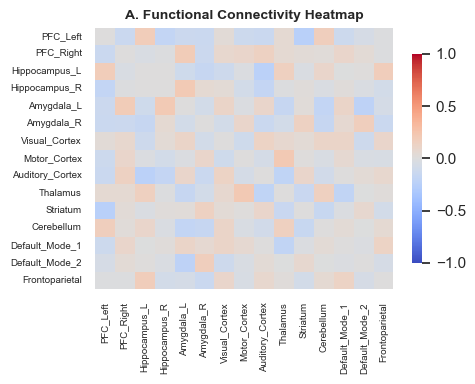

In [7]:
# VIZUAL 1: Kiçik Connectivity Heatmap (İlk 15 region)
plt.figure(figsize=(5, 4))
sns.heatmap(
    correlation_matrix[:15, :15], 
    xticklabels=brain_regions[:15], 
    yticklabels=brain_regions[:15],
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    cbar=True,
    cbar_kws={'shrink': 0.8}
)
plt.title("A. Functional Connectivity Heatmap", fontsize=10, fontweight='bold')
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig("visual_1_heatmap.png", dpi=300)
plt.show()

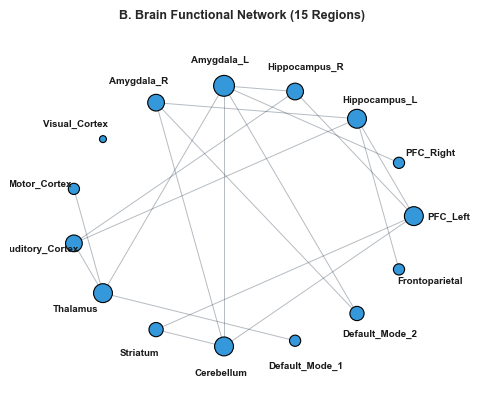

In [21]:
# VIZUAL 2: Daha yığcam və səliqəli Network Graph
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

connection_threshold = 0.15 
sub_matrix = correlation_matrix[:15, :15]
adj_matrix = np.where(np.abs(sub_matrix) > connection_threshold, sub_matrix, 0)

G = nx.from_numpy_array(adj_matrix)
node_mapping = {i: brain_regions[i] for i in range(15)}
G = nx.relabel_nodes(G, node_mapping)

degrees = dict(G.degree())
node_sizes = [v * 40 + 25 for v in degrees.values()]

# Şəkil ölçüsünü kiçildirik ki, poster üzərində səliqəli dursun
plt.figure(figsize=(5, 4.2))
pos = nx.circular_layout(G) 

# Əlaqə xətləri
nx.draw_networkx_edges(G, pos, width=0.7, alpha=0.35, edge_color='#2c3e50') 

# Mavi toplar (nodes)
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='#3498db', alpha=1.0, edgecolors='black', linewidths=0.8)

# Yazıların yerini tənzimləyirik
pos_labels = {node: (coords[0] * 1.2, coords[1] * 1.2) for node, coords in pos.items()}

# Etiketlər
nx.draw_networkx_labels(G, pos_labels, font_size=7, font_weight='bold', horizontalalignment='center', verticalalignment='center')

plt.title("B. Brain Functional Network (15 Regions)", fontsize=9, fontweight='bold', pad=15)
plt.axis('off')
plt.xlim(-1.35, 1.35)
plt.ylim(-1.35, 1.35)

plt.tight_layout()
plt.savefig("visual_2_network_dense.png", dpi=300, bbox_inches='tight')
plt.show()

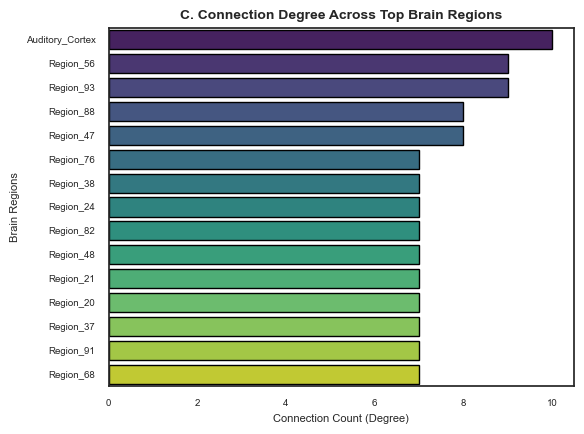

In [22]:
# VIZUAL 3: Bütün 100 regionun əlaqə dərəcələrinin paylanması (Tam dolu və elmi vizual)
full_adj = np.where(np.abs(correlation_matrix) > 0.2, 1, 0)  # Eşik dəyərini yumşaldırıq ki, əlaqələr itib getməsin
full_G = nx.from_numpy_array(full_adj)
full_degrees = [full_G.degree(i) for i in range(len(brain_regions))]

df_all = pd.DataFrame({
    'Region': brain_regions,
    'Degree': full_degrees
}).sort_values(by='Degree', ascending=False)

# Yalnız 0 olanları deyil, bütün regionların paylanmasını əks etdirən zəngin Bar Plot (Top 15 ən aktiv region)
plt.figure(figsize=(6, 4.5))
sns.barplot(
    data=df_all.head(15), 
    x='Degree', 
    y='Region', 
    palette='viridis', 
    hue='Region', 
    legend=False,
    edgecolor='black'
)

plt.title("C. Connection Degree Across Top Brain Regions", fontsize=10, fontweight='bold')
plt.xlabel("Connection Count (Degree)", fontsize=8)
plt.ylabel("Brain Regions", fontsize=8)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig("visual_3_barplot.png", dpi=300)
plt.show()

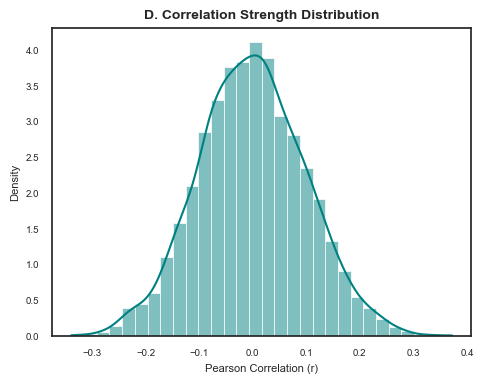

In [10]:
# VIZUAL 4: Connectivity Strength Distribution (Histogram)
flat_corr = correlation_matrix[np.triu_indices_from(correlation_matrix, k=1)]

plt.figure(figsize=(5, 4))
sns.histplot(flat_corr, bins=30, color='teal', kde=True, stat="density", linewidth=0.5)
plt.title("D. Correlation Strength Distribution", fontsize=10, fontweight='bold')
plt.xlabel("Pearson Correlation (r)", fontsize=8)
plt.ylabel("Density", fontsize=8)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig("visual_4_distribution.png", dpi=300)
plt.show()